In [1]:
import calendar
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter,FuncFormatter

## The chart-choosing framework 

First ask: **what is my question?** Then pick the chart.

| Question type | Best charts |
|---|---|
| Compare categories | Bar chart, countplot, catplot |
| Distribution of one number | Histplot, KDE, boxplot, violinplot |
| Relationship between two numbers | Scatterplot (add `hue` / `size` for a third variable) |
| Relationship across many numbers | Heatmap, pairplot |
| Trend over time | Lineplot |
| Parts of a whole | Bar / stacked bar first, pie only for 2 to 4 categories |

# Common mistakes

1. pie chart with too many slices
2. bar chart that does not start at zero
3. too many colors, unreadable labels, missing titles or axis labels
4. line plots for categories that have no order
5. Dual-axis charts that mislead

# Questions

1. Which category earns the most sales and the most profit ?
2. How do sales change across the year ?
3. How are order sizes distributed ?
4. Which regions and segements perform best ?
5. How does discount affect profit ?
6. Which sub-category make or lose money ?
7. Where (category x region) is profit strongest and weakest ?
8. How do sales, profit, discount and quantity relate?

In [2]:
df = pd.read_csv("retail_sales.csv",parse_dates=["order_date"])

In [5]:
df.head()

,order_id,order_date,region,segment,category,sub_category,quantity,discount,sales,profit
0,2001,2025-01-01,West,Corporate,Office Supplies,Storage,7,0.2,335.76,14.07
1,2002,2025-01-01,East,Corporate,Office Supplies,Storage,4,0.4,169.75,-8.42
2,2003,2025-01-01,East,Corporate,Office Supplies,Storage,2,0.0,144.23,28.26
3,2004,2025-01-01,Central,Corporate,Furniture,Bookcases,6,0.1,1252.64,17.57
4,2005,2025-01-02,West,Corporate,Office Supplies,Art,1,0.0,10.19,2.29


In [6]:
sns.set_theme(style="whitegrid",context="notebook")

## 1. Which category earns the most sales and the most profit ?

In [9]:
cat_summary = df.groupby("category")[["sales","profit","quantity"]].sum().reset_index()

cat_summary

,category,sales,profit,quantity
0,Furniture,216061.75,5947.93,785
1,Office Supplies,62035.83,7900.55,2229
2,Technology,246736.04,43096.61,806


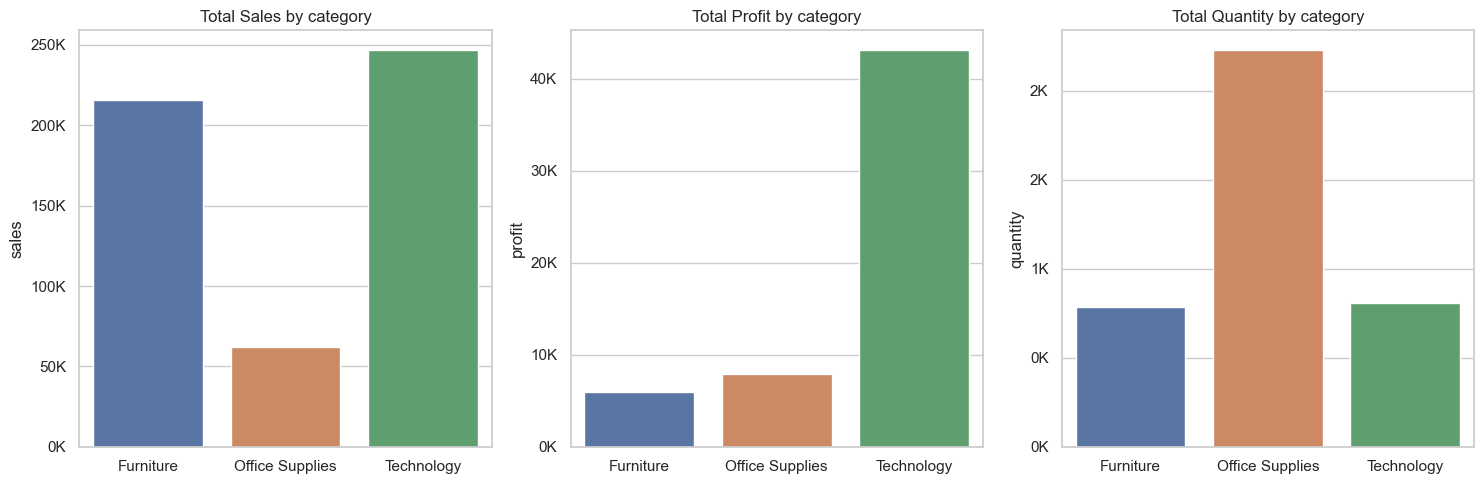

In [19]:
fig,axes = plt.subplots(1,3,figsize=(15,5))

sns.barplot(
    data=cat_summary,
    x="category",
    y="sales",
    hue="category",
    ax=axes[0]
)
axes[0].set_title("Total Sales by category")

sns.barplot(
    data=cat_summary,
    x="category",
    y="profit",
    hue="category",
    ax=axes[1]
)
axes[1].set_title("Total Profit by category")


sns.barplot(
    data=cat_summary,
    x="category",
    y="quantity",
    hue="category",
    ax=axes[2]
)
axes[2].set_title("Total Quantity by category")

for ax in axes:
    ax.set_xlabel("")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v,_:f"{v/1000:.0f}K"))

plt.tight_layout()
plt.show()


## 2. How do sales change across the year ?

In [23]:
monthly = df.groupby(df['order_date'].dt.month)['sales'].sum()
monthly.index = [calendar.month_abbr[m] for m in monthly.index]

monthly

Jan     34590.22
Feb     20680.75
Mar     37474.57
Apr     21576.31
May     36888.75
Jun     32835.44
Jul     35788.47
Aug     53060.29
Sep     38817.64
Oct     44436.85
Nov     65658.18
Dec    103026.15
Name: sales, dtype: float64

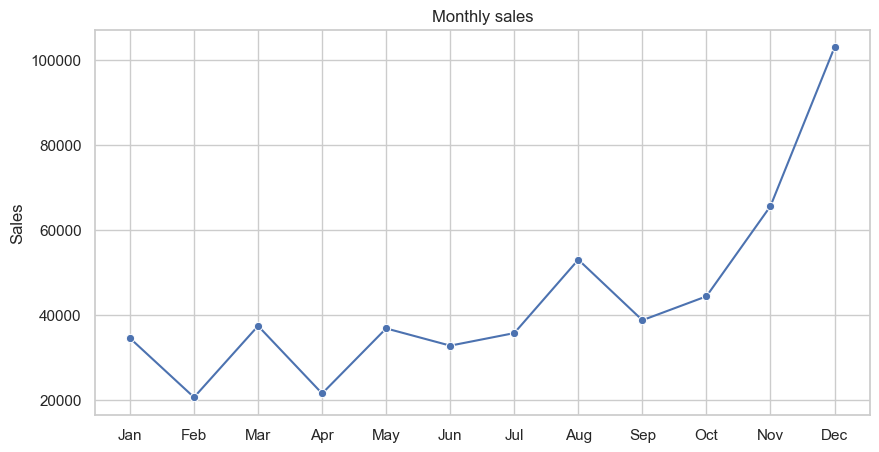

In [ ]:
plt.figure(figsize=(10,5))

sns.lineplot(x=monthly.index,y=monthly.values,marker="o")
plt.title("Monthly sales")
plt.ylabel("Sales")
plt.xlabel("")
plt.show()

In [29]:
df

,order_id,order_date,region,segment,category,sub_category,quantity,discount,sales,profit
0,2001,2025-01-01,West,Corporate,Office Supplies,Storage,7,0.2,335.76,14.07
1,2002,2025-01-01,East,Corporate,Office Supplies,Storage,4,0.4,169.75,-8.42
2,2003,2025-01-01,East,Corporate,Office Supplies,Storage,2,0.0,144.23,28.26
3,2004,2025-01-01,Central,Corporate,Furniture,Bookcases,6,0.1,1252.64,17.57
4,2005,2025-01-02,West,Corporate,Office Supplies,Art,1,0.0,10.19,2.29
...,...,...,...,...,...,...,...,...,...,...
995,2996,2025-12-30,East,Corporate,Technology,Accessories,4,0.0,440.45,114.41
996,2997,2025-12-30,West,Consumer,Office Supplies,Binders,2,0.0,35.14,8.32
997,2998,2025-12-31,South,Consumer,Office Supplies,Paper,1,0.0,18.07,3.58
998,2999,2025-12-31,West,Home Office,Office Supplies,Art,2,0.0,21.80,4.69


In [33]:
monthly_cat = df.groupby([df['order_date'].dt.month,"category"])['sales'].sum().reset_index()

monthly_cat['month'] = monthly_cat['order_date'].map(lambda m:calendar.month_abbr[m])

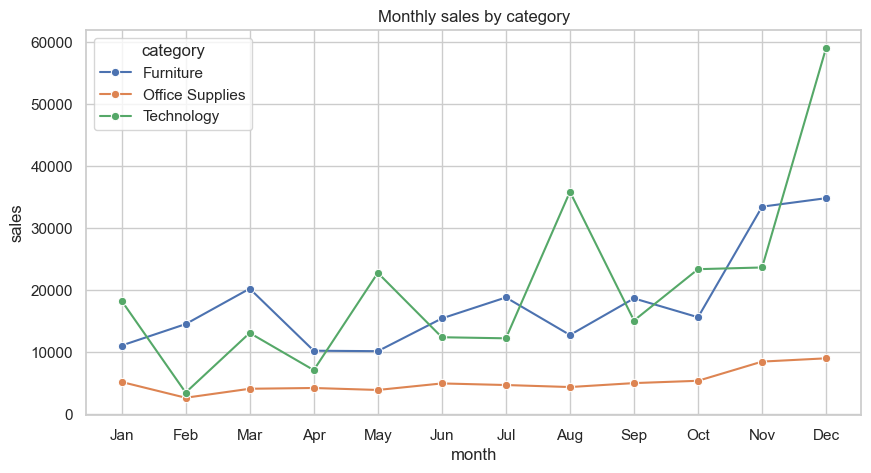

In [37]:
plt.figure(figsize=(10,5))
sns.lineplot(data=monthly_cat,x="month",y='sales',hue="category",marker="o")
plt.title("Monthly sales by category")
plt.show()


## 3. How are order sizes distributed ?

In [41]:
df['sales'].max()

17496.29

In [42]:
df['sales'].min()

8.33

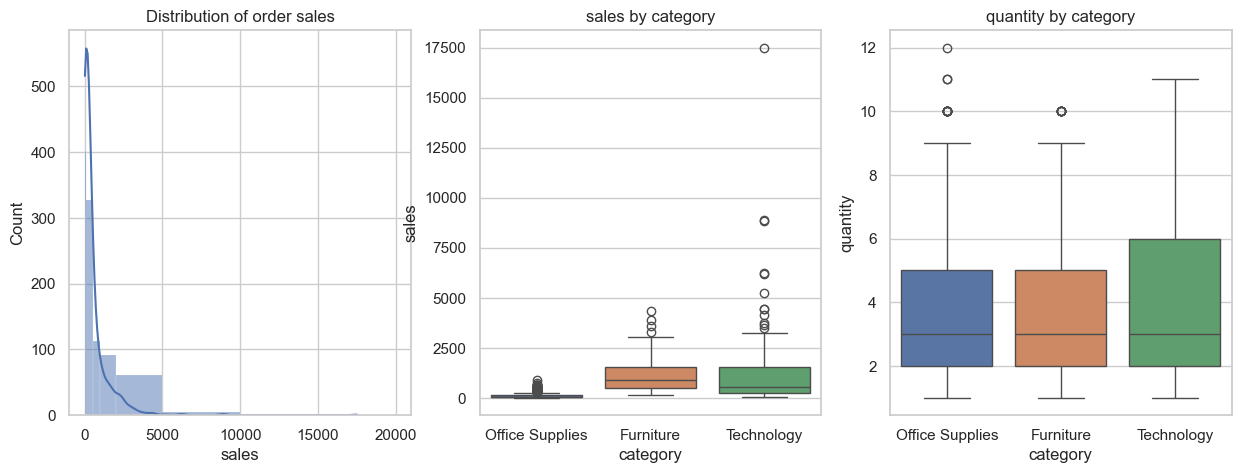

In [49]:
fig,ax = plt.subplots(1,3,figsize=(15,5))

sns.histplot(data=df,x="sales",bins=[1,100,500,1000,2000,5000,10000,20000],kde=True,ax=ax[0])
ax[0].set_title("Distribution of order sales")

sns.boxplot(data=df,x="category",y="sales",hue="category",ax=ax[1])
ax[1].set_title("sales by category")

sns.boxplot(data=df,x="category",y="quantity",hue="category",ax=ax[2])
ax[2].set_title("quantity by category")
plt.show()


## 4. Which regions and segements perform best ?

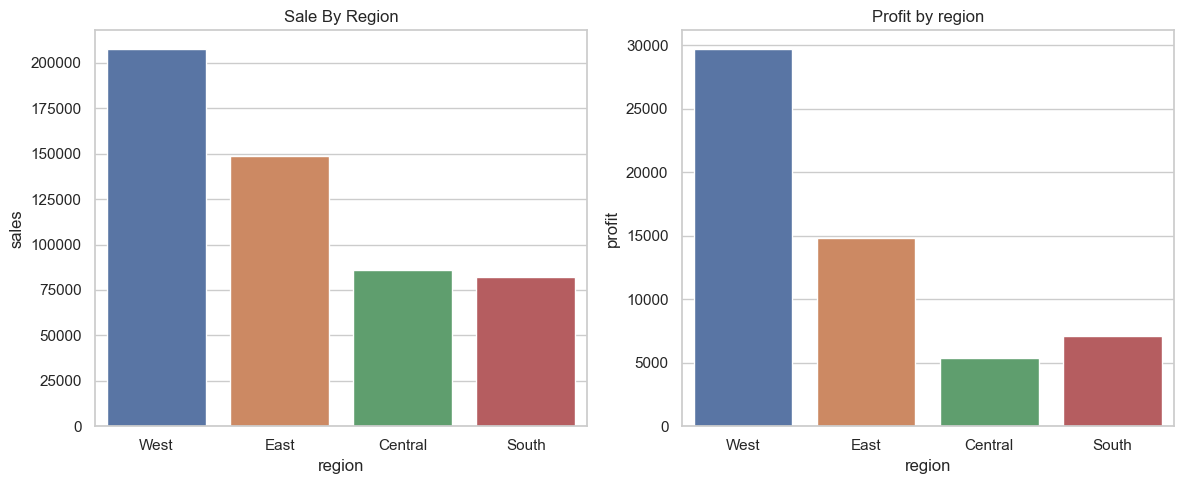

In [59]:
fig,axes = plt.subplots(1,2,figsize=(12,5))

sns.barplot(
    data=df,
    x="region",
    y="sales",
    estimator="sum",
    errorbar=None,
    ax=axes[0],
    hue="region"
)
axes[0].set_title("Sale By Region")
sns.barplot(
    data=df,
    x="region",
    y="profit",
    estimator="sum",
    errorbar=None,
    ax=axes[1],
    hue="region"
)
axes[1].set_title("Profit by region")
plt.tight_layout()
plt.show()

In [70]:
region_margin = df.groupby("region")[["sales","profit"]].sum().reset_index()

In [71]:
region_margin['margin'] = region_margin['profit']/region_margin['sales']

In [77]:
region_margin.sort_values(by="margin",ascending=False,inplace=True)

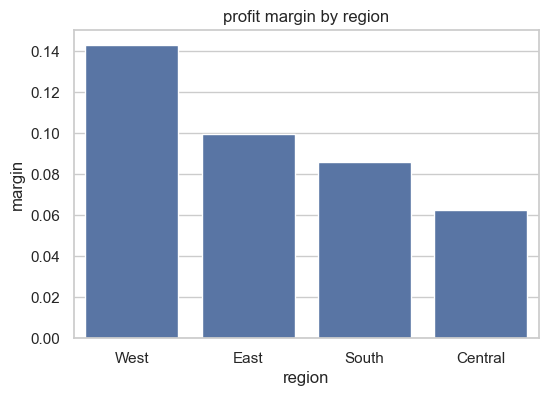

In [78]:
plt.figure(figsize=(6,4))

sns.barplot(data=region_margin,x="region",y="margin")
plt.title("profit margin by region")
plt.show()

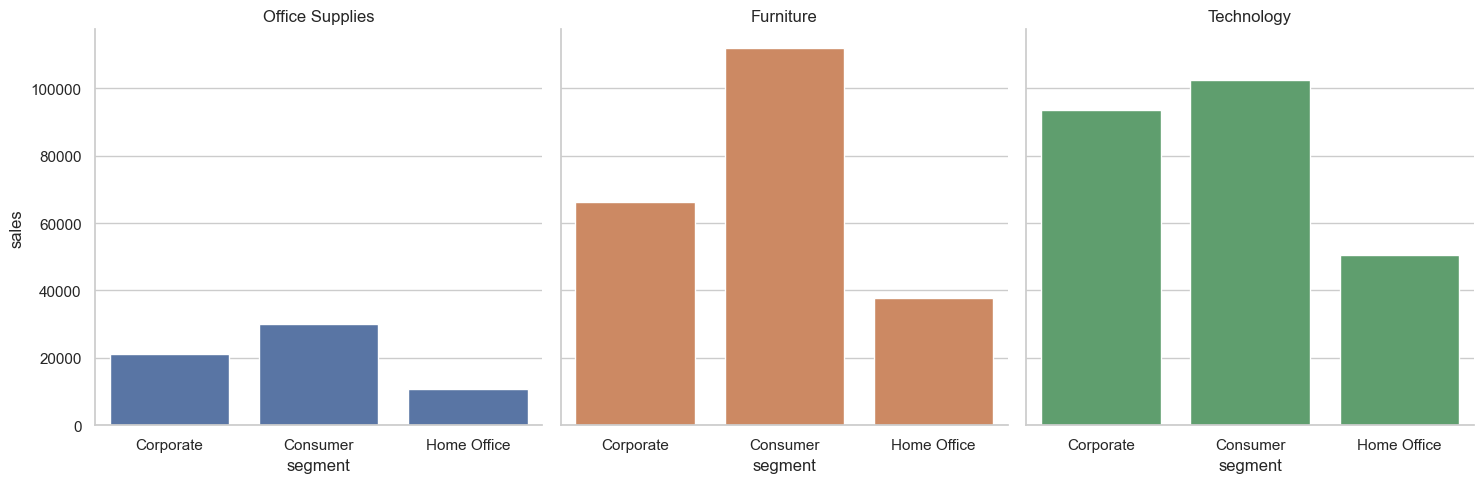

In [84]:
g = sns.catplot(data=df,
            x="segment",
            y="sales",
            col='category',
            kind="bar",
            estimator="sum",
            hue="category",
            errorbar=None,legend=False)

g.set_titles("{col_name}")
plt.show()


## 5. How does discount affect profit ?

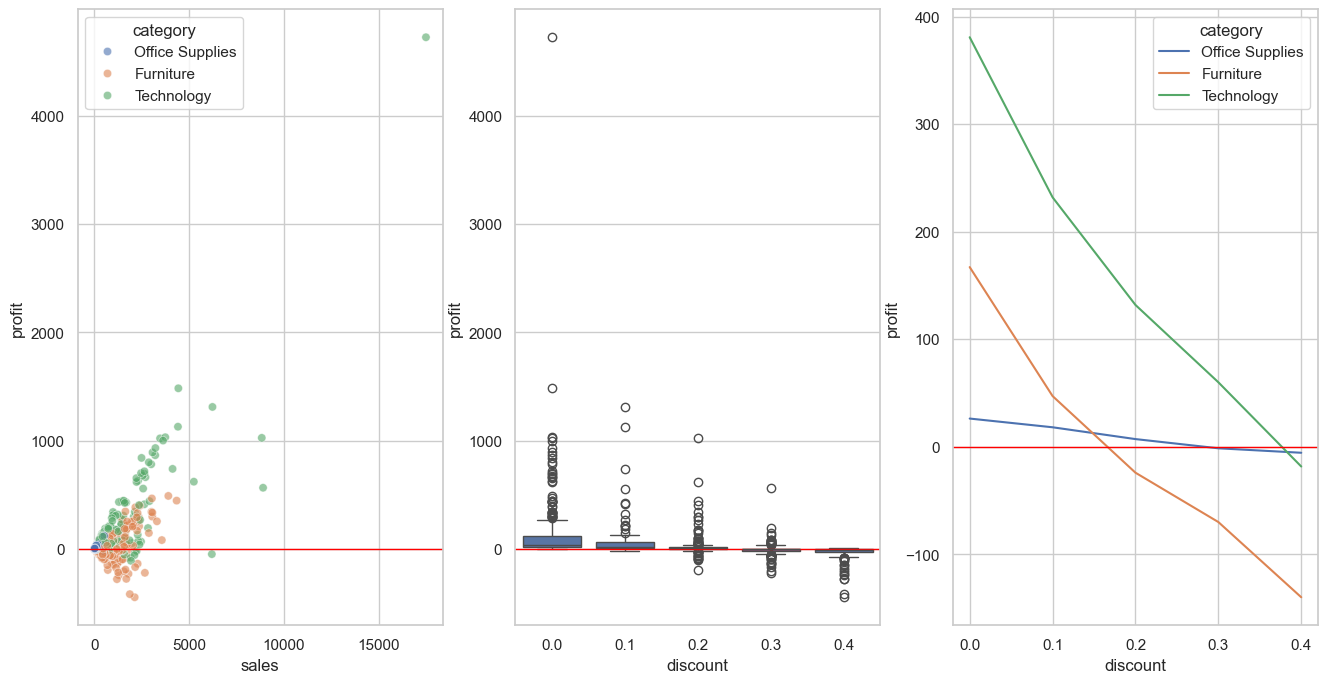

In [96]:
fig,ax = plt.subplots(1,3,figsize=(16,8))

sns.scatterplot(data=df,x="sales",y="profit",ax=ax[0],alpha=0.6,hue="category")
ax[0].axhline(0,color="red",linewidth=1)


sns.boxplot(data=df,x="discount",y="profit",ax=ax[1])
ax[1].axhline(0,color="red",linewidth=1)


sns.lineplot(data=df,x="discount",y="profit",ax=ax[2],hue="category",errorbar=None)
ax[2].axhline(0,color="red",linewidth=1)

plt.show()


In [97]:
df.head()

,order_id,order_date,region,segment,category,sub_category,quantity,discount,sales,profit
0,2001,2025-01-01,West,Corporate,Office Supplies,Storage,7,0.2,335.76,14.07
1,2002,2025-01-01,East,Corporate,Office Supplies,Storage,4,0.4,169.75,-8.42
2,2003,2025-01-01,East,Corporate,Office Supplies,Storage,2,0.0,144.23,28.26
3,2004,2025-01-01,Central,Corporate,Furniture,Bookcases,6,0.1,1252.64,17.57
4,2005,2025-01-02,West,Corporate,Office Supplies,Art,1,0.0,10.19,2.29


In [99]:
loss_rate = df.assign(loss=df['profit']<0).groupby("discount")['loss'].mean()

In [100]:
loss_rate

discount
0.0    0.000000
0.1    0.016854
0.2    0.133333
0.3    0.567376
0.4    0.967213
Name: loss, dtype: float64

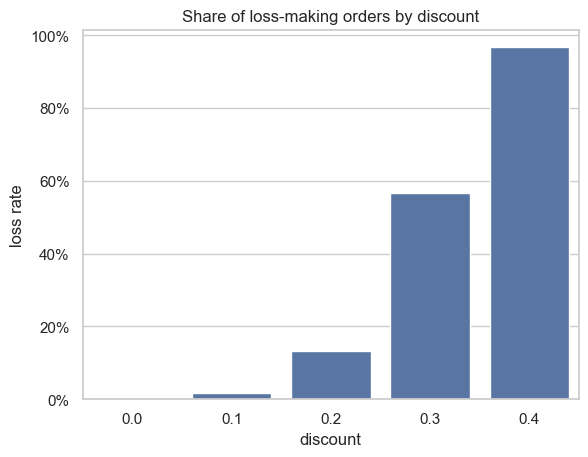

In [104]:
sns.barplot(x=loss_rate.index,y=loss_rate.values)
plt.ylabel("loss rate")
plt.xlabel("discount")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.title("Share of loss-making orders by discount")
plt.show()

## 6. Which sub-category make or lose money ?

In [105]:
df.head()

,order_id,order_date,region,segment,category,sub_category,quantity,discount,sales,profit
0,2001,2025-01-01,West,Corporate,Office Supplies,Storage,7,0.2,335.76,14.07
1,2002,2025-01-01,East,Corporate,Office Supplies,Storage,4,0.4,169.75,-8.42
2,2003,2025-01-01,East,Corporate,Office Supplies,Storage,2,0.0,144.23,28.26
3,2004,2025-01-01,Central,Corporate,Furniture,Bookcases,6,0.1,1252.64,17.57
4,2005,2025-01-02,West,Corporate,Office Supplies,Art,1,0.0,10.19,2.29


In [116]:
sct = df.groupby(['sub_category','category'])['profit'].sum().reset_index().sort_values("profit",ascending=False)

In [117]:
sct

,sub_category,category,profit
7,Phones,Technology,24374.56
5,Copiers,Technology,13531.14
0,Accessories,Technology,5190.91
8,Storage,Office Supplies,4403.22
3,Bookcases,Furniture,2655.57
4,Chairs,Furniture,2045.11
6,Paper,Office Supplies,1807.10
9,Tables,Furniture,1247.25
2,Binders,Office Supplies,1156.20
1,Art,Office Supplies,534.03


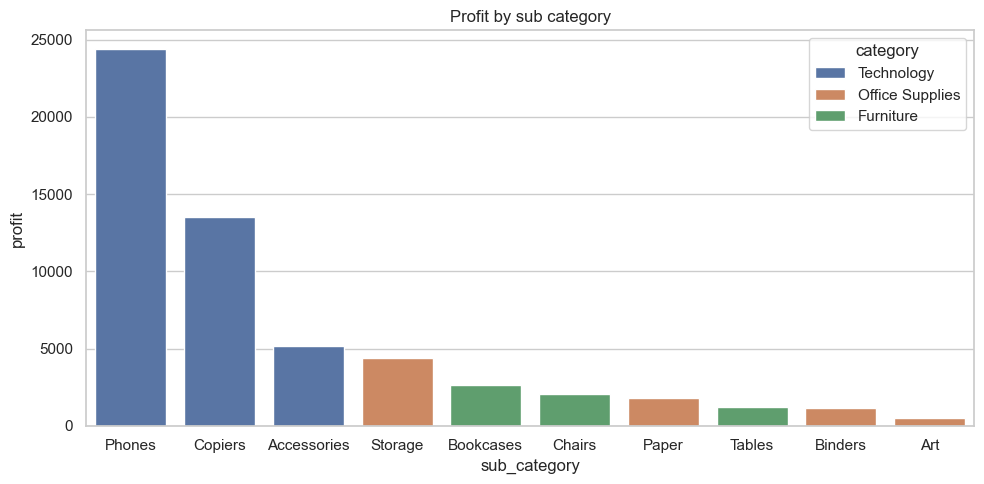

In [122]:
plt.figure(figsize=(10,5))
sns.barplot(data=sct,x="sub_category",y="profit",hue="category")
plt.title("Profit by sub category")
plt.tight_layout()
plt.show()


## 7. Where (category x region) is profit strongest and weakest ?

In [155]:
pvt_table = df.pivot_table(index="category",columns="region",values="profit",aggfunc="sum")

In [125]:
pvt_table

region,Central,East,South,West
category,,,,
Furniture,79.51,2036.09,854.08,2978.25
Office Supplies,1188.37,2348.26,1524.27,2839.65
Technology,4111.62,10418.71,4700.05,23866.23


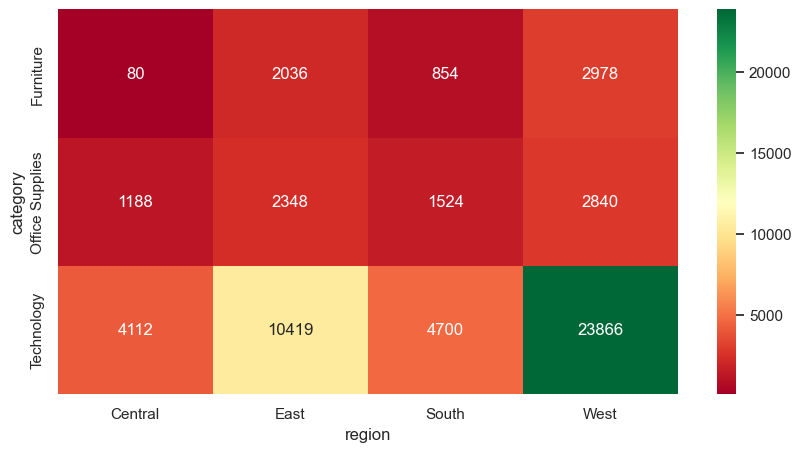

In [128]:
plt.figure(figsize=(10,5))
sns.heatmap(pvt_table,annot=True,fmt=".0f",cmap="RdYlGn")

plt.show()

In [129]:
pvt_table = df.pivot_table(index="category",columns="region",values="discount",aggfunc="sum")

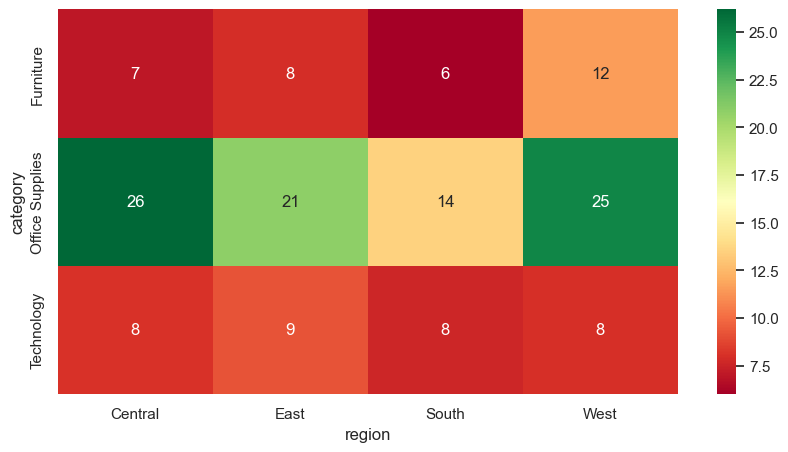

In [130]:
plt.figure(figsize=(10,5))
sns.heatmap(pvt_table,annot=True,fmt=".0f",cmap="RdYlGn")

plt.show()


## 8. How do sales, profit, discount and quantity relate?

In [131]:
df.head()

,order_id,order_date,region,segment,category,sub_category,quantity,discount,sales,profit
0,2001,2025-01-01,West,Corporate,Office Supplies,Storage,7,0.2,335.76,14.07
1,2002,2025-01-01,East,Corporate,Office Supplies,Storage,4,0.4,169.75,-8.42
2,2003,2025-01-01,East,Corporate,Office Supplies,Storage,2,0.0,144.23,28.26
3,2004,2025-01-01,Central,Corporate,Furniture,Bookcases,6,0.1,1252.64,17.57
4,2005,2025-01-02,West,Corporate,Office Supplies,Art,1,0.0,10.19,2.29


In [132]:
num_cols = ['quantity',"discount","sales","profit"]

corr = df[num_cols].corr()

In [135]:
mask = np.triu(np.ones_like(corr,dtype=bool))

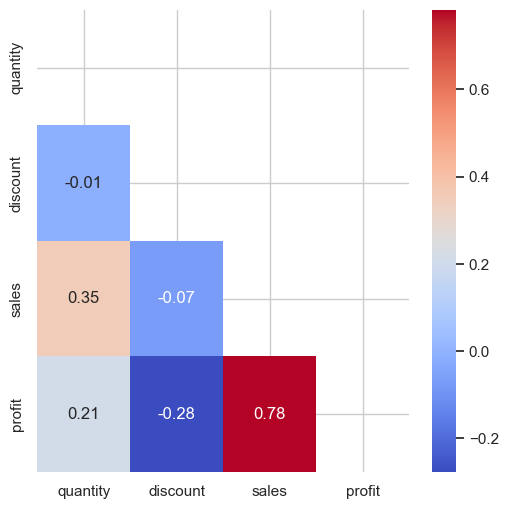

In [139]:
plt.figure(figsize=(6,6))
sns.heatmap(corr,mask=mask,annot=True,fmt=".02f",cmap="coolwarm")
plt.show()

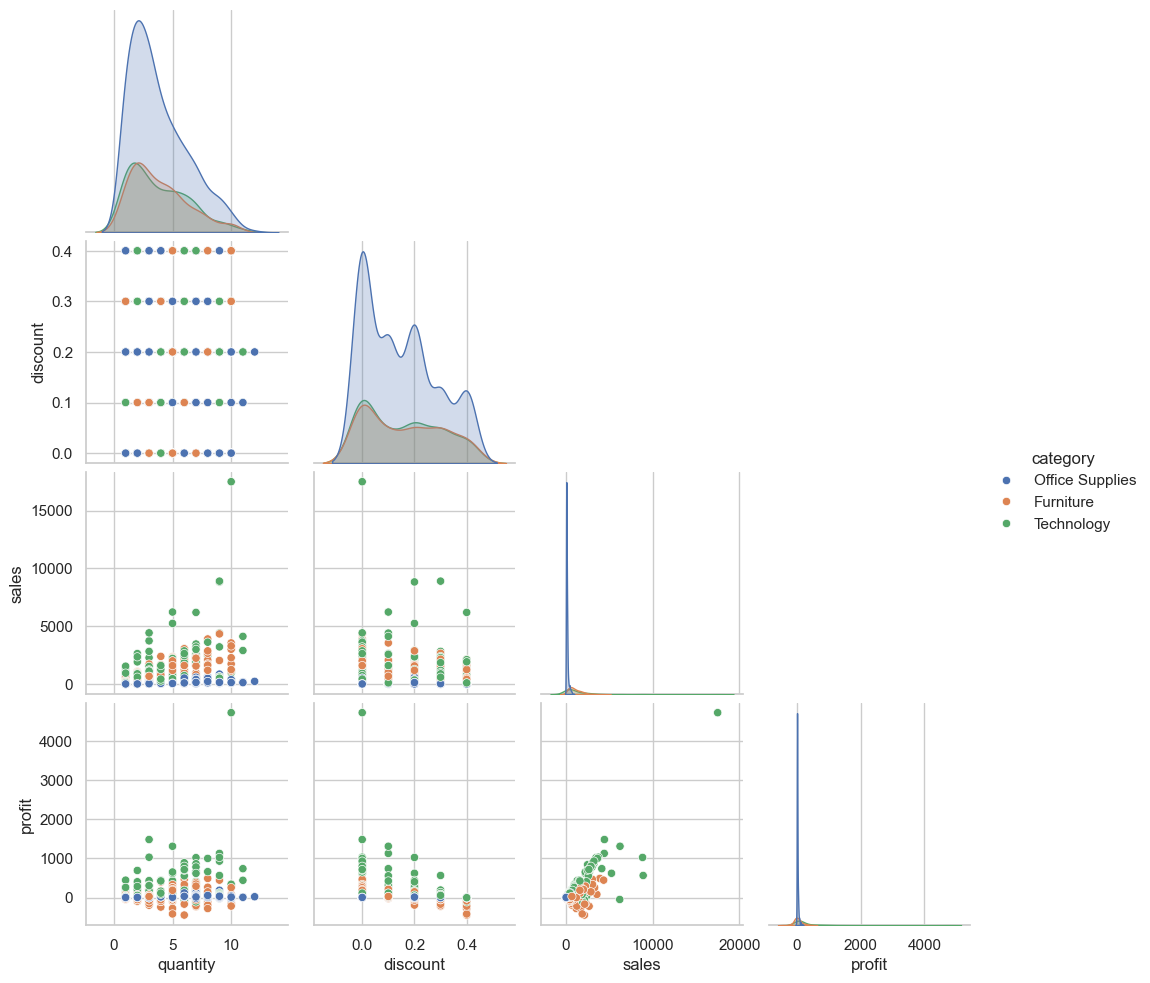

In [142]:
sns.pairplot(df,vars=num_cols,hue="category",corner=True)

In [144]:
monthly

Jan     34590.22
Feb     20680.75
Mar     37474.57
Apr     21576.31
May     36888.75
Jun     32835.44
Jul     35788.47
Aug     53060.29
Sep     38817.64
Oct     44436.85
Nov     65658.18
Dec    103026.15
Name: sales, dtype: float64

In [146]:
cat_summary

,category,sales,profit,quantity
0,Furniture,216061.75,5947.93,785
1,Office Supplies,62035.83,7900.55,2229
2,Technology,246736.04,43096.61,806




# Dashboard

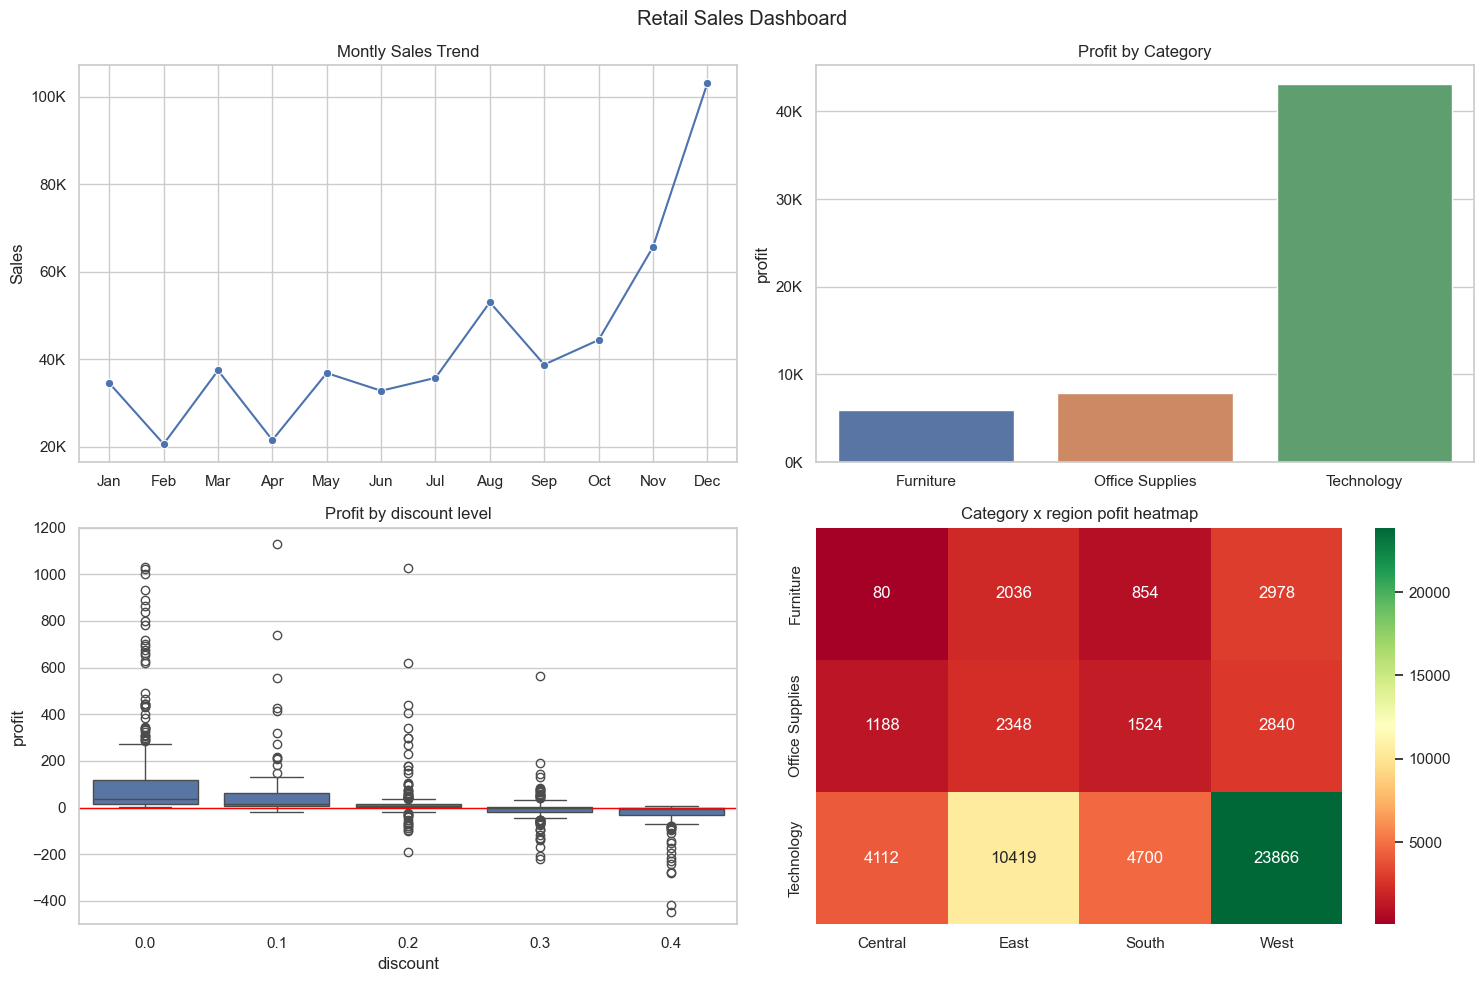

In [161]:
fig,axes = plt.subplots(2,2,figsize=(15,10))

# Monthly Sales Trend
sns.lineplot(x=monthly.index,y=monthly.values,marker="o",ax=axes[0,0])
axes[0,0].set_title("Montly Sales Trend")
axes[0,0].set_xlabel("")
axes[0,0].set_ylabel("Sales")
axes[0,0].yaxis.set_major_formatter(FuncFormatter(lambda v,_:f"{v/1000:.0f}K"))



# Profit By Category
sns.barplot(data=cat_summary,x="category",y="profit",hue="category",legend=False,ax=axes[0,1])
axes[0,1].set_xlabel("")
axes[0,1].yaxis.set_major_formatter(FuncFormatter(lambda v,_:f"{v/1000:.0f}K"))
axes[0,1].set_title("Profit by Category")

# Profit by discount level

sns.boxplot(data =df,x="discount",y="profit",ax=axes[1,0])
axes[1,0].axhline(0,color="red",linewidth=1)
axes[1,0].set_ylim(-500,1200)
axes[1,0].set_title("Profit by discount level")

# Category x region pofit heatmap
sns.heatmap(pvt_table,annot=True,fmt=".0f",cmap="RdYlGn",ax=axes[1,1])
axes[1,1].set_title("Category x region pofit heatmap")
axes[1,1].set_xlabel("")
axes[1,1].set_ylabel("")


fig.suptitle("Retail Sales Dashboard")
plt.tight_layout()
plt.savefig("dashboard.png")
plt.show()